# Mini Project: Hopfield Network for Pattern Recovery

This simple project shows how a **Hopfield Network** recovers a stored pattern from noisy data.

**Flow:** Original Pattern → Add Noise → Hopfield Network → Recovered Pattern


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)


## 1. Create Original Pattern

We use a simple 5×5 letter **H** pattern.

- `1` = active pixel
- `-1` = inactive pixel


In [2]:
pattern = np.array([
    [ 1, -1, -1,  1,  1],
    [ 1, -1, -1,  1,  1],
    [ 1,  1,  1,  1,  1],
    [ 1, -1, -1,  1,  1],
    [ 1, -1, -1,  1,  1]
])

print(pattern)


[[ 1 -1 -1  1  1]
 [ 1 -1 -1  1  1]
 [ 1  1  1  1  1]
 [ 1 -1 -1  1  1]
 [ 1 -1 -1  1  1]]


## 2. Store the Pattern in Hopfield Network

The 5×5 pattern is converted into 25 neurons. The weights are created using the basic Hopfield learning rule.


In [3]:
pattern_flat = pattern.flatten()

W = np.outer(pattern_flat, pattern_flat)
np.fill_diagonal(W, 0)

print("Weight Matrix Shape:", W.shape)


Weight Matrix Shape: (25, 25)


## 3. Add Noise

Some pixels are flipped to create a noisy input pattern.


In [4]:
noisy_pattern = pattern.copy()

noise_positions = [(0, 1), (1, 3), (2, 0), (3, 2), (4, 4)]

for r, c in noise_positions:
    noisy_pattern[r, c] *= -1

print(noisy_pattern)


[[ 1  1 -1  1  1]
 [ 1 -1 -1 -1  1]
 [-1  1  1  1  1]
 [ 1 -1  1  1  1]
 [ 1 -1 -1  1 -1]]


## 4. Hopfield Recall

The network updates the neurons repeatedly until the pattern becomes stable.


In [5]:
def recall(input_pattern, W, steps=10):
    state = input_pattern.flatten().copy()

    for _ in range(steps):
        old_state = state.copy()

        for i in range(len(state)):
            total = np.dot(W[i], state)

            if total >= 0:
                state[i] = 1
            else:
                state[i] = -1

        if np.array_equal(state, old_state):
            break

    return state.reshape(input_pattern.shape)

recovered_pattern = recall(noisy_pattern, W)

print(recovered_pattern)


[[ 1 -1 -1  1  1]
 [ 1 -1 -1  1  1]
 [ 1  1  1  1  1]
 [ 1 -1 -1  1  1]
 [ 1 -1 -1  1  1]]


## 5. Data Before and After

This graph compares the **original data**, **noisy data**, and **recovered data**.


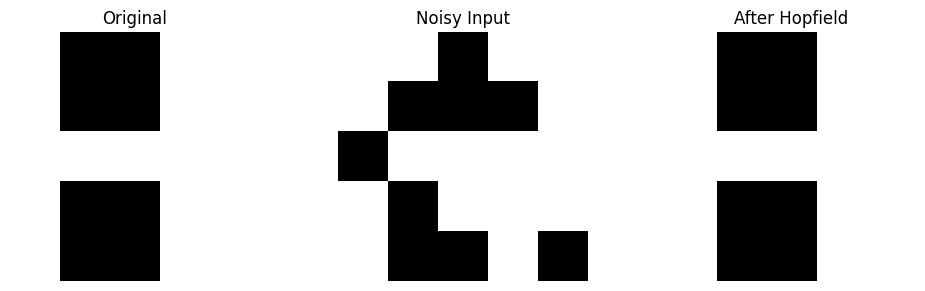

In [6]:
plt.figure(figsize=(10, 3))

plt.subplot(1, 3, 1)
plt.imshow(pattern, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(noisy_pattern, cmap="gray")
plt.title("Noisy Input")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(recovered_pattern, cmap="gray")
plt.title("After Hopfield")
plt.axis("off")

plt.tight_layout()
plt.show()


## Conclusion

The Hopfield Network stores a pattern as an associative memory. When a noisy version of that pattern is given as input, the network tries to recover the stored pattern.

**Original → Noisy → Recovered**

This is a simple demonstration of **associative memory and pattern recovery** using a Hopfield Network.
